# Домашнее задание 1. Message passing своими руками

**ФИО:** Трубачеев Борис Андреевич

**Группа:** S4201 

**Что сделано:** выполнены все задания и бонусы

# Реализация

Скачаем и установим все нужное 

In [1]:
%pip -q install torch-geometric pytest

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import random, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import subgraph

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("Selected device:", DEVICE)

SEEDS = [9, 22, 31, 52, 67]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def load_data(name):
    ds = Planetoid(root="data/Planetoid", name=name)
    return ds, ds[0]

def accuracy(logits, labels, mask):
    mask = mask.cpu()
    if not mask.any(): return float("nan")
    return (logits[mask].argmax(-1) == labels.cpu()[mask]).float().mean().item()

def mean_std(values):
    return float(np.mean(values)), float(np.std(values, ddof=1))


PyTorch: 2.14.1+cpu
CUDA build: None
Selected device: cpu


Сделаем импорты самописных классов из submission.py

In [ ]:
TASK_DIR = Path.cwd() 

submission = TASK_DIR / "submission.py"
if TASK_DIR is None:
    raise FileNotFoundError("Не нашёл submission.py. Откройте ноутбук из папки задания task1.")
sys.path.insert(0, str(TASK_DIR))

from submission import MyGCNConv, MySAGEConv


## Часть 1. Реализация и проверка — 2 балла


Запустим тесты из тестового файла

In [5]:
test_file = TASK_DIR / "test_task1.py"
if not test_file.is_file():
    raise FileNotFoundError(f"Не найден тестовый файл в {TASK_DIR}")

In [ ]:
import pytest
result = pytest.main(["-v", str(test_file)])
if result != pytest.ExitCode.OK:
    raise RuntimeError(f"Тесты завершились с кодом {result}")


============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-8.3.4, pluggy-1.5.0 -- c:\Users\boris\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: c:\Users\boris\Desktop\Учеба\Мага\2 курс\Графовые нейронки\task1
plugins: anyio-4.7.0
collecting ... collected 7 items

test_task1.py::test_gcn_output_shape PASSED                              [ 14%]
test_task1.py::test_gcn_matches_pyg PASSED                               [ 28%]
test_task1.py::test_gcn_on_directed_graph PASSED                         [ 42%]
test_task1.py::test_gcn_permutation_invariance PASSED                    [ 57%]
test_task1.py::test_gcn_isolated_node_is_finite PASSED                   [ 71%]
test_task1.py::test_sage_matches_pyg PASSED                              [ 85%]
test_task1.py::test_gcn_is_trainable PASSED                              [100%]

============================== warnings summary ===============================
test_task1.py: 35 warnings


Все тейсты пройдены успешно!!!

А значит реализация работает корректно

## Часть 2. Воспроизведение результата — 1.5 балла


Класс для двухслойной модели с самописными слоями (без дропаутов тест не проходился для рандомного конфига сидов, поэтому для большей уверенности добавил дропаутов)

In [8]:
class TwoLayerModel(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, kind="gcn"):
        super().__init__()
        conv = MyGCNConv if kind == "gcn" else MySAGEConv
        self.input_dropout = nn.Dropout(p=0.5)
        self.conv1 = conv(in_channels, hidden_channels)
        self.hidden_dropout = nn.Dropout(p=0.5)
        self.conv2 = conv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.input_dropout(x)
        h = F.relu(self.conv1(x, edge_index))
        h = self.hidden_dropout(h)
        return self.conv2(h, edge_index), h

Двуслойный MLP для бейслайна

In [9]:
class TwoLayerMLP(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.lin1 = nn.Linear(in_channels, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels, out_channels)

    def forward(self, x, edge_index=None):
        h = F.relu(self.lin1(x))
        return self.lin2(h), h

Функция обучения с ранней остановкой, чтобы избежать переобучения

In [10]:
def make_model(kind, in_channels, hidden_channels, out_channels):
    if kind == "mlp": return TwoLayerMLP(in_channels, hidden_channels, out_channels)
    return TwoLayerModel(in_channels, hidden_channels, out_channels, kind)

def fit(data, kind="gcn", seed=11, train_mask=None, val_mask=None, hidden=16,
        epochs=400, patience=50, lr=0.01, weight_decay=5e-4):
    set_seed(seed)
    
    x, ei, y = data.x.to(DEVICE), data.edge_index.to(DEVICE), data.y.to(DEVICE)
    train_mask = (data.train_mask if train_mask is None else train_mask).to(DEVICE)
    val_mask = (data.val_mask if val_mask is None else val_mask).to(DEVICE)
    model = make_model(kind, x.size(-1), hidden, int(y.max()) + 1).to(DEVICE)
    
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_loss, best_state, stale = float("inf"), None, 0
    
    for _ in range(epochs):
        model.train(); optimizer.zero_grad()
        logits, _ = model(x, ei)
        F.cross_entropy(logits[train_mask], y[train_mask]).backward(); optimizer.step()
        model.eval()
        
        with torch.no_grad(): 
            logits, _ = model(x, ei); val_loss = F.cross_entropy(logits[val_mask], y[val_mask]).item()
            
        if val_loss < best_loss - 1e-7:
            best_loss, stale = val_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= patience:
                break

    model.load_state_dict(best_state)
    model.to(DEVICE).eval()

    with torch.no_grad(): 
        logits, hidden_state = model(x, ei)
    
    return model, logits.cpu(), hidden_state.cpu(), accuracy(logits.cpu(), y.cpu(), data.test_mask)


Загружаем датасеты Cora и CiteSeer и прогоняем кастомную двуслойную реализацию и двуслойный MLP для каждого сида

In [11]:
records = []

for name in ["Cora", "CiteSeer"]:
    dataset, data = load_data(name)
    print(f"{name}: nodes={data.num_nodes}, features={dataset.num_features}, classes={dataset.num_classes}")
    
    for kind in ["gcn", "mlp"]:
        scores = [fit(data, kind=kind, seed=seed)[3] for seed in SEEDS]
        mean, std = mean_std(scores)
        records.append({"dataset": name, "model": kind.upper(), "scores": scores, "mean": mean, "std": std})

main_results = pd.DataFrame(records)
display(main_results[["dataset", "model", "mean", "std"]].style.format({"mean":"{:.3f}", "std":"{:.3f}"}))


Cora: nodes=2708, features=1433, classes=7
CiteSeer: nodes=3327, features=3703, classes=6


,dataset,model,mean,std
0,Cora,GCN,0.803,0.007
1,Cora,MLP,0.529,0.020
2,CiteSeer,GCN,0.684,0.010
3,CiteSeer,MLP,0.577,0.010


In [12]:
target_cora = 0.815
gcn = main_results[(main_results.dataset == "Cora") & (main_results.model == "GCN")].iloc[0]
mlp = main_results[(main_results.dataset == "Cora") & (main_results.model == "MLP")].iloc[0]

print("Результаты для Cora:")
print(f"В статье: {target_cora}")
print(f"Замеры на моей реализации: {gcn['mean']:.3f} +- {gcn['std']:.3f}")
print(f"Попали в +- 2%: {abs(gcn['mean'] - target_cora) <= 0.02}")
print(f"Побили бейслайн в виде MLP на: {gcn['mean'] - mlp['mean']:.3f}")


Результаты для Cora:
В статье: 0.815
Замеры на моей реализации: 0.803 +- 0.007
Попали в +- 2%: True
Побили бейслайн в виде MLP на: 0.275


Видим, что для Cora результат стабилен по сидам, входит в рамки +-2п.п. от результатов статьи и намного превосходит MLP

In [13]:
target_citeseer = 0.703
gcn = main_results[(main_results.dataset == "CiteSeer") & (main_results.model == "GCN")].iloc[0]
mlp = main_results[(main_results.dataset == "CiteSeer") & (main_results.model == "MLP")].iloc[0]

print("Результаты для CiteSeer:")
print(f"В статье: {target_citeseer}")
print(f"Замеры на моей реализации: {gcn['mean']:.3f} +- {gcn['std']:.3f}")
print(f"Попали в +- 2%: {abs(gcn['mean'] - target_citeseer) <= 0.02}")
print(f"Побили бейслайн в виде MLP на: {gcn['mean'] - mlp['mean']:.3f}")

Результаты для CiteSeer:
В статье: 0.703
Замеры на моей реализации: 0.684 +- 0.010
Попали в +- 2%: True
Побили бейслайн в виде MLP на: 0.108


Видим, что для CiteSeer результат стабилен по сидам, входит в рамки +-2п.п. от результатов статьи и намного превосходит MLP

## Часть 3. Что ломается при увеличении глубины — 1.5 балла

Создадим класс для создания сетей с разным кол-вом кастомных слоев

In [14]:
class DeepGCN(nn.Module):
    def __init__(self, in_channels, hidden, out_channels, depth):
        super().__init__()
        if depth < 2: raise ValueError("depth должен быть не меньше 2")
        dims = [in_channels] + [hidden] * (depth - 1) + [out_channels]
        self.layers = nn.ModuleList(MyGCNConv(a, b) for a, b in zip(dims[:-1], dims[1:]))

    def forward(self, x, edge_index):
        for layer in self.layers[:-1]:
            x = F.relu(layer(x, edge_index))
        hidden = x
        return self.layers[-1](hidden, edge_index), hidden

Перепишем fit для работы с большим кол-вом слоев

In [15]:
def fit_deep(data, depth, seed=11, train_mask=None, val_mask=None, hidden=16,
             epochs=400, patience=50, lr=0.01, weight_decay=5e-4):
    set_seed(seed)
    x, ei, y = data.x.to(DEVICE), data.edge_index.to(DEVICE), data.y.to(DEVICE)
    train_mask = (data.train_mask if train_mask is None else train_mask).to(DEVICE)
    val_mask = (data.val_mask if val_mask is None else val_mask).to(DEVICE)
    model = DeepGCN(x.size(-1), hidden, int(y.max()) + 1, depth).to(DEVICE)
    
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_loss, best_state, stale = float("inf"), None, 0

    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits, _ = model(x, ei)
        F.cross_entropy(logits[train_mask], y[train_mask]).backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            logits, _ = model(x, ei)
            val_loss = F.cross_entropy(logits[val_mask], y[val_mask]).item()

        if val_loss < best_loss - 1e-7:
            best_loss, stale = val_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= patience:
                break

    model.load_state_dict(best_state)
    model.to(DEVICE).eval()

    with torch.no_grad():
        logits, h = model(x, ei)

    h = h.cpu()
    z = F.normalize(h, p=2, dim=1)
    n = z.size(0)
    cosine = ((z.sum(0).square().sum() - z.square().sum()) / (n * (n - 1))).item()
    zero_fraction = (h.norm(dim=1) <= 1e-12).float().mean().item()

    return accuracy(logits.cpu(), y.cpu(), data.test_mask), cosine, zero_fraction

Загрузим датасет Cora и прогоним тесты для разного числа кастомных слоев: [2, 4, 8, 16] и для каждого сида

In [17]:
_, cora = load_data("Cora")
depth_rows = []

for depth in [2, 4, 8, 16]:
    for seed in SEEDS:
        acc, cosine, zero = fit_deep(cora, depth, seed)
        depth_rows.append({"depth":depth, "seed":seed, "accuracy":acc, "cosine":cosine, "zero_fraction":zero})

Посмотрим на результаты

In [19]:
depth_raw = pd.DataFrame(depth_rows)
depth_summary = depth_raw.groupby("depth").agg(accuracy_mean=("accuracy","mean"), accuracy_std=("accuracy","std"),
    cosine_mean=("cosine","mean"), cosine_std=("cosine","std"), zero_mean=("zero_fraction","mean"), zero_std=("zero_fraction","std")).reset_index()
display(depth_summary.style.format({c:"{:.3f}" for c in depth_summary.columns if c != "depth"}))

,depth,accuracy_mean,accuracy_std,cosine_mean,cosine_std,zero_mean,zero_std
0,2,0.807,0.005,0.734,0.032,0.000,0.000
1,4,0.739,0.013,0.759,0.039,0.000,0.000
2,8,0.159,0.097,0.924,0.044,0.000,0.000
3,16,0.196,0.096,0.959,0.033,0.000,0.000


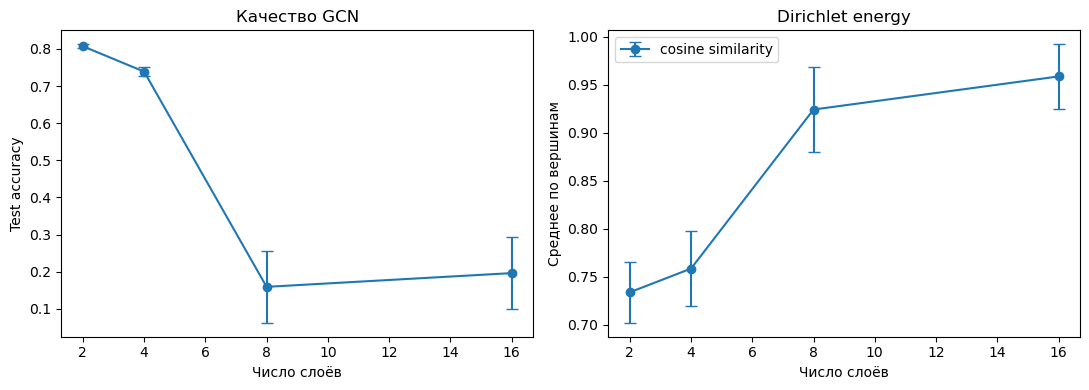

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))

axes[0].errorbar(depth_summary.depth, depth_summary.accuracy_mean, yerr=depth_summary.accuracy_std, marker="o", capsize=4)
axes[0].set(xlabel="Число слоёв", ylabel="Test accuracy", title="Качество GCN")

axes[1].errorbar(depth_summary.depth, depth_summary.cosine_mean, yerr=depth_summary.cosine_std, marker="o", capsize=4, label="cosine similarity")
axes[1].set(xlabel="Число слоёв", ylabel="Среднее по вершинам", title="Dirichlet energy"); axes[1].legend()

plt.tight_layout()
plt.show()

Видим, что качество и косинусное сходство имеют противоположные тренды при росле числа слоев. Объясняется это тем, что при увеличении числа слоев внутренние представления становятся все более абстрактными и сглаженными, похожими друг на друга. Это снижает их индивидуальные особенности и как следствие мешает модели учить паттерны в этих особенностях, из-за чего качество падает


## 4. Бонус A. Inductive-режим — 2.5 балла

Отложим тестовые вершины в маску, проверив, что их 1000

In [22]:
_, cora = load_data("Cora")
test_nodes = cora.test_mask.nonzero(as_tuple=False).view(-1)
assert test_nodes.numel() == 1000, f"ожидалось 1000 test-узлов, получено {test_nodes.numel()}"

keep_nodes = (~cora.test_mask).nonzero(as_tuple=False).view(-1)
edge_ind, _ = subgraph(keep_nodes, cora.edge_index, relabel_nodes=True, num_nodes=cora.num_nodes)
ind = type(cora)(); ind.x = cora.x[keep_nodes]; ind.y = cora.y[keep_nodes]; ind.edge_index = edge_ind
ind.train_mask = cora.train_mask[keep_nodes]; ind.val_mask = cora.val_mask[keep_nodes]
ind.test_mask = torch.zeros(keep_nodes.numel(), dtype=torch.bool)
ind_scores, trans_scores = [], []

Для каждого сида прогоним в Inductive режиме (без верщин) и в Transductive режиме (без лейблов)

In [ ]:

for seed in SEEDS:
    model, _, _, _ = fit(ind, kind="sage", seed=seed)
    with torch.no_grad(): 
        logits, _ = model(cora.x.to(DEVICE), cora.edge_index.to(DEVICE))
    ind_scores.append(accuracy(logits.cpu(), cora.y, cora.test_mask))
    
    model, _, _, _ = fit(cora, kind="sage", seed=seed)
    with torch.no_grad(): 
        logits, _ = model(cora.x.to(DEVICE), cora.edge_index.to(DEVICE))
    trans_scores.append(accuracy(logits.cpu(), cora.y, cora.test_mask))
    
im, isd = mean_std(ind_scores)
tm, tsd = mean_std(trans_scores)

display(pd.DataFrame([
    {"Режим":"inductive", "Видела test-вершины при обучении":"нет", "Accuracy mean":im, "SD":isd},
    {"Режим":"transductive", "Видела test-вершины при обучении":"да, но без меток", "Accuracy mean":tm, "SD":tsd},
]).style.format({"Accuracy mean":"{:.3f}", "SD":"{:.3f}"}))


,Режим,Видела test-вершины при обучении,Accuracy mean,SD
0,inductive,нет,0.768,0.005
1,transductive,"да, без меток",0.793,0.005


Предсказуемо, тот факт что модель не видела тест-вершины при обученни привел к ухудшению качества, так как модель не видела их признаки и связи. При наличии же самих вершин без лейблов качество улучшилось на 2.5п.п. , так как модель смогла учитывать связи тестовых вершин в обученнии и их признаки без лейблов

## Бонус B. Сколько разметки нужно графу — 2.5 балла

Функция для задания маски для скрытия доли размеченных вершин

In [24]:
def sample_train_mask(data, fraction, seed):
    pool = (~data.val_mask & ~data.test_mask).nonzero(as_tuple=False).view(-1).numpy()
    labels = data.y.numpy(); rng = np.random.default_rng(seed)
    classes = np.unique(labels[pool]); target = max(len(classes), int(round(fraction * len(pool))))
    by_class = {c: pool[labels[pool] == c] for c in classes}
    quota = {c: min(len(by_class[c]), int(np.floor(target * len(by_class[c]) / len(pool)))) for c in classes}
    
    for c in classes:
        if quota[c] == 0 and len(by_class[c]): quota[c] = 1
    
    while sum(quota.values()) > target:
        c = max((c for c in classes if quota[c] > 1), key=lambda k: quota[k] - target*len(by_class[k])/len(pool)); quota[c] -= 1
    
    while sum(quota.values()) < target:
        choices = [c for c in classes if quota[c] < len(by_class[c])]
        if not choices: break
        c = max(choices, key=lambda k: target*len(by_class[k])/len(pool) - quota[k]); quota[c] += 1
    
    selected = np.concatenate([rng.choice(by_class[c], quota[c], replace=False) for c in classes])
    mask = torch.zeros(data.num_nodes, dtype=torch.bool); mask[selected] = True
    
    return mask

Для разых сидов и % скрытых вершин прогоним GSN и MLP

In [32]:
_, cora = load_data("Cora"); label_rows = []
for fraction in [0.01, 0.05, 0.2, 0.6, 0.95]:
    for kind in ["gcn", "mlp"]:
        for seed in SEEDS:
            train_mask = sample_train_mask(cora, fraction, seed)
            score = fit(cora, kind=kind, seed=seed, train_mask=train_mask)[3]
            label_rows.append({"fraction":fraction, "model":kind.upper(), "seed":seed,
                               "accuracy":score, "labels":int(train_mask.sum())})

Посмотирм на результаты

In [33]:
label_raw = pd.DataFrame(label_rows)
label_summary = label_raw.groupby(["fraction","model"]).agg(mean=("accuracy","mean"), std=("accuracy","std"), labels=("labels","mean")).reset_index()
display(label_summary.style.format({"fraction":"{:.0%}", "mean":"{:.3f}", "std":"{:.3f}", "labels":"{:.1f}"}))

,fraction,model,mean,std,labels
0,1%,GCN,0.619,0.067,12.0
1,1%,MLP,0.376,0.045,12.0
2,5%,GCN,0.764,0.021,60.0
3,5%,MLP,0.458,0.040,60.0
4,20%,GCN,0.831,0.004,242.0
5,20%,MLP,0.600,0.032,242.0
6,60%,GCN,0.862,0.009,725.0
7,60%,MLP,0.679,0.012,725.0
8,95%,GCN,0.872,0.008,1148.0
9,95%,MLP,0.724,0.011,1148.0


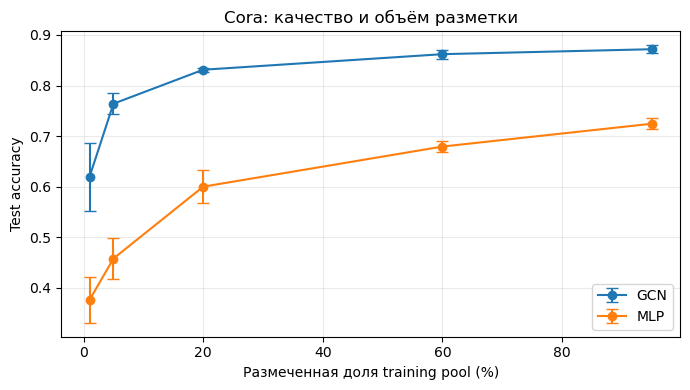

1%: GCN − MLP = +0.244 accuracy points
5%: GCN − MLP = +0.306 accuracy points
20%: GCN − MLP = +0.231 accuracy points
60%: GCN − MLP = +0.183 accuracy points


In [34]:

fig, ax = plt.subplots(figsize=(7,4))
for name, group in label_summary.groupby("model"):
    ax.errorbar(group.fraction*100, group["mean"], yerr=group["std"], marker="o", capsize=4, label=name)
ax.set(xlabel="Размеченная доля training pool (%)", ylabel="Test accuracy", title="Cora: качество и объём разметки")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()
for fraction in [.01,.05,.20,.60]:
    rows = label_summary[label_summary.fraction == fraction].set_index("model")
    print(f"{fraction:.0%}: GCN − MLP = {rows.loc['GCN','mean']-rows.loc['MLP','mean']:+.3f} accuracy points")


Видим, что при увеличении размеченной доли вершин преимущечтво GSN сохраняется и не исчезает. При этом 
 преимущество постепенно сокращается и MLP приближается к GSN, так как при большем кол-ве меток MLP модели проще опираться на признаки вершин, но учитывание графовой структуры все равно выигрывает у обучения на обычных признаках даже при высокой доле разметки. 

# Итог

Все задания выполнены